# Cross-Session Localization

Localization counterpart of `Fingerprint_Analysis.ipynb`: how much the cross-session fingerprint shift costs in accuracy, and whether positions with a larger shift are localized worse.

1. **RF Fusion runs:** the main cross-session run on the three repeated volunteers, plus two references.
2. **Localization maps.**
3. **Shift versus error.**

Every plot is followed by its **ideal reference**:

- for localization, a perfect classifier (every window correct, zero error);
- for the shift, `ideal_reference_features` from `Fingerprint_Analysis.ipynb`, where the fingerprint depends on the position only.

In [1]:
import pandas as pd
from IPython.display import display  # noqa: A004

from utils.config import (
    BANDS_TO_RUN,
    DATA_DIR,
    DEFAULT_OVERLAP_SIZE,
    DEFAULT_WINDOW_SIZE,
    INTERNAL_RESULTS_DIR,
    PROJECT_ROOT,
    notebook_report_dir,
)
from utils.domain_shift import (
    PERFORMANCE_LABELS,
    SHIFT_METRIC_LABELS,
    cross_session_similarity,
    filter_users,
    ideal_predictions,
    ideal_reference_features,
    localization_by_location,
    location_shift_table,
    shift_localization_correlations,
    shift_localization_table,
)
from utils.fingerprint import feature_inventory_table, normalize_two_digit_id
from utils.ML.ml_pipeline import (
    build_preproc_opts,
    get_cache_path,
    load_feature_dataframes,
    load_params_lookup,
    load_raw_csi_data,
    run_global_baselines,
)
from utils.plots import plot_floor_plan_heatmap, plot_shift_vs_localization
from utils.results import compute_localization_metrics, save_table

## Configuration

### CSI Pipeline

Same preprocessing and feature-extraction options as the ML notebook, so the cached feature DataFrames are reused.

In [2]:
CALIBRATION_MODE = "rssi"  # none | packet_norm | rssi

CSV_PROCESSING_OPTIONS = {
    "max_workers": None,  # None = all CPU cores (32 on the server)
    "cache_dir": None,
    "use_cache": True,
    "force_reprocess": False,
    "min_rssi_dbm": -95.0,
    "calibration_eps": 1e-12,
}

MAGNITUDE_PROCESSING_OPTIONS = {
    "normalization": "empty_baseline",  # none | zscore | minmax | packet_minmax | empty_baseline
    "epsilon": 1e-8,
}
NORMALIZATION_BASELINE_SCOPE = "per_session"  # per_session | per_user | global

FEATURE_EXTRACTION_OPTIONS = {
    "window_size": DEFAULT_WINDOW_SIZE,
    "overlap_size": DEFAULT_OVERLAP_SIZE,
    "require_all_esps": False,
}

preproc_opts = build_preproc_opts(
    MAGNITUDE_PROCESSING_OPTIONS,
    baseline_scope=NORMALIZATION_BASELINE_SCOPE,
)
feat_opts = dict(FEATURE_EXTRACTION_OPTIONS)
print(f"Feature cache path: {get_cache_path(preproc_opts, feat_opts)}")

Feature cache path: /home/pedro.monteiro@co.it.pt/Desktop/thesis-project/.cache/dataframes/preproc=norm-empty_baseline_scope-per_session/feat=win60-step0


### Experiment

| Run | Train | Test |
|---|---|---|
| **Cross-session, 3 users (main)** | Trial 01 of users 01/03/05 | Trial 02 of users 01/03/05 |
| Cross-session, 6 users (reference) | Trial 01 of all six users | Trial 02 of users 01/03/05 |
| Within-session block, 3 users (upper bound) | Trial 01 blocks of users 01/03/05 | held-out Trial-01 blocks |

The hyperparameters are the frozen thesis grid-search values (`thesis/results`, read-only). Runs reload from `results/internal/` when a matching run ID exists. The 6-user run keeps its thesis run ID; the 3-user runs hash the user subset into a new one.

In [3]:
SESSION_USERS = ("01", "03", "05")
COMPARISON_TRIALS = ("01", "02")
TRIAL_A, TRIAL_B = COMPARISON_TRIALS

# RF Fusion
TUNED_PARAMS_DIR = PROJECT_ROOT / "thesis" / "results"
RF_BAND = "Fusion"
BLOCK_COUNT = 10
TEST_SIZE = 0.30
RANDOM_STATE = 42
N_JOBS = -1  # -1 = all CPU cores (does not change results or run IDs)
MAIN_RUN = "cross-session, 3 users"

# Shift versus error
SIMILARITY_FEATURE_FAMILY = "mean"
SHIFT_METRIC = "shift_ratio"
PERFORMANCE_METRICS = ("position_accuracy", "mean_distance_error")

# Ideal reference
SHOW_IDEAL = True
IDEAL_NOISE_SCALE = 0.25

# Display and outputs
DISPLAY_PLOTS = True
SAVE_PLOTS = False
SAVE_TABLES = False

VIEWS = ("Measured", "Ideal") if SHOW_IDEAL else ("Measured",)
report_dir = notebook_report_dir("Cross_Session_Localization")
plots_dir = report_dir / "plots"
tables_dir = report_dir / "tables"

## Data

In [4]:
magnitude_data, csv_diagnostics = load_raw_csi_data(
    DATA_DIR,
    calibration_mode=CALIBRATION_MODE,
    csv_options=CSV_PROCESSING_OPTIONS,
)

Scenarios present: 1
Locations: 53 | Users: 6 | ESPs: 19


In [5]:
feature_dataframes = load_feature_dataframes(
    magnitude_data,
    preproc_opts=preproc_opts,
    feat_opts=feat_opts,
    bands_to_run=BANDS_TO_RUN,
)
display(feature_inventory_table(feature_dataframes))

[features] resolved cache path: /home/pedro.monteiro@co.it.pt/Desktop/thesis-project/.cache/dataframes/preproc=norm-empty_baseline_scope-per_session/feat=win60-step0
[cache hit] /home/pedro.monteiro@co.it.pt/Desktop/thesis-project/.cache/dataframes/preproc=norm-empty_baseline_scope-per_session/feat=win60-step0/2_4ghz.parquet
[cache hit] /home/pedro.monteiro@co.it.pt/Desktop/thesis-project/.cache/dataframes/preproc=norm-empty_baseline_scope-per_session/feat=win60-step0/5ghz.parquet
[cache hit] /home/pedro.monteiro@co.it.pt/Desktop/thesis-project/.cache/dataframes/preproc=norm-empty_baseline_scope-per_session/feat=win60-step0/fusion.parquet
2.4 GHz: 13588 windows, 2708 columns
5 GHz: 14478 windows, 3368 columns
Fusion: 13568 windows, 6068 columns


,band,fingerprints,recordings,positions,users,trials,ESPs,feature_columns,metadata_columns
0,2.4 GHz,13588,467,52,6,"01, 02",9,2700,8
1,5 GHz,14478,467,52,6,"01, 02",10,3360,8
2,Fusion,13568,467,52,6,"01, 02",19,6060,8


In [6]:
del magnitude_data

## 1. RF Fusion Runs

In [7]:
rf_params = load_params_lookup(
    TUNED_PARAMS_DIR,
    models_to_run=("RF",),
    bands_to_run=(RF_BAND,),
    preproc_opts=preproc_opts,
    feat_opts=feat_opts,
    require_tuned_params=True,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    n_blocks=BLOCK_COUNT,
)
RF_RUNS = {
    "cross-session, 3 users": ("cross_session", SESSION_USERS),
    "cross-session, 6 users": ("cross_session", None),
    "within-session block, 3 users": ("block", SESSION_USERS),
}
rf_predictions = {}
for label, (split_mode, users) in RF_RUNS.items():
    _, predictions = run_global_baselines(
        feature_dataframes,
        params_lookup=rf_params,
        models_to_run=("RF",),
        bands_to_run=(RF_BAND,),
        split_modes=(split_mode,),
        users=users,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        n_blocks=BLOCK_COUNT,
        n_jobs=N_JOBS,
        results_dir=INTERNAL_RESULTS_DIR,
        preproc_opts=preproc_opts,
        feat_opts=feat_opts,
        force_retrain=False,
        save_predictions=True,
        svm_fallback_seconds=30 * 60,
        row_spacing=1.0,
        column_spacing=1.0,
    )
    rf_predictions[label] = predictions[("RF", RF_BAND, split_mode)]
if SHOW_IDEAL:
    rf_predictions["ideal (perfect classifier)"] = ideal_predictions(rf_predictions[MAIN_RUN])

[tuned params] exact runs.csv match: RF / Fusion / run_id=ml__rf__fusion__grid_search__ebl-session__s42__666a25
[users] Fusion: restricted to users ['01', '03', '05'] (9309 windows)
[cross_session] discovered trial-02 users: 01, 03, 05
[protocol] split=cross_session trials_used=['01', '02'] n_train=4630 n_test=4679 users=['01', '03', '05'] train_users=['01', '03', '05'] test_users=['01', '03', '05']
[cross_session] n_train=4630 users=['01', '03', '05'] positions=52
[cross_session] n_test=4679 users=['01', '03', '05'] positions=52
[cross_session] assertion passed: no trial-02 window is in training
[cross_session] all test positions are represented in training
[predictions cache hit] /home/pedro.monteiro@co.it.pt/Desktop/thesis-project/results/predictions/ml__rf__fusion__cross_session__ebl-session__s42__699ffe.parquet
[baseline] Fusion / RF / cross_session: majority_position_accuracy=0.0194, majority_room_accuracy=0.6542
[cross_session] discovered trial-02 users: 01, 03, 05
[protocol] sp

### Metrics per Volunteer

Ideal: the "ideal (perfect classifier)" column, with accuracy 1 and error 0 m.

In [8]:
LOCALIZATION_COLUMNS = ("position_accuracy", "room_accuracy", "mean_distance_error")
localization_rows = []
for label, predictions in rf_predictions.items():
    groups = [("all", predictions)]
    groups += list(predictions.groupby(predictions["user"].map(normalize_two_digit_id)))
    for user, group in groups:
        metrics = compute_localization_metrics(group)
        localization_rows.append(
            {"run": label, "user": user, **{key: metrics[key] for key in LOCALIZATION_COLUMNS}}
        )
localization_summary = pd.DataFrame(localization_rows)
display(
    localization_summary.pivot_table(
        index="user", columns="run", values=list(LOCALIZATION_COLUMNS)
    ).round(3)
)

mean_distance_error                                                    \
run  cross-session, 3 users cross-session, 6 users ideal (perfect classifier)   
user                                                                            
01                    3.963                  3.917                        0.0   
03                    3.868                  3.701                        0.0   
05                    4.160                  3.752                        0.0   
all                   3.999                  3.790                        0.0   

                                        position_accuracy  \
run  within-session block, 3 users cross-session, 3 users   
user                                                        
01                           0.194                  0.130   
03                           0.192                  0.186   
05                           0.093                  0.116   
all                          0.161                  0.143   

                                                        \
run  cross-session, 6 users ideal (perfect classifier)   
user                                                     
01                    0.146                        1.0   
03                    0.188                        1.0   
05                    0.145                        1.0   
all                   0.159                        1.0   

                                            room_accuracy  \
run  within-session block, 3 users cross-session, 3 users   
user                                                        
01                           0.896                  0.648   
03                           0.886                  0.615   
05                           0.944                  0.511   
all                          0.908                  0.591   

                                                        \
run  cross-session, 6 users ideal (perfect classifier)   
user                                                     
01                    0.668                        1.0   
03                    0.661                        1.0   
05                    0.605                        1.0   
all                   0.644                        1.0   

                                    
run  within-session block, 3 users  
user                                
01                           1.000  
03                           0.992  
05                           1.000  
all                          0.997

## 2. Localization Maps

Main run (cross-session, 3 users), pooled over the three volunteers.

Ideal: every cell at 100% accuracy and 0 m error.

[Measured]


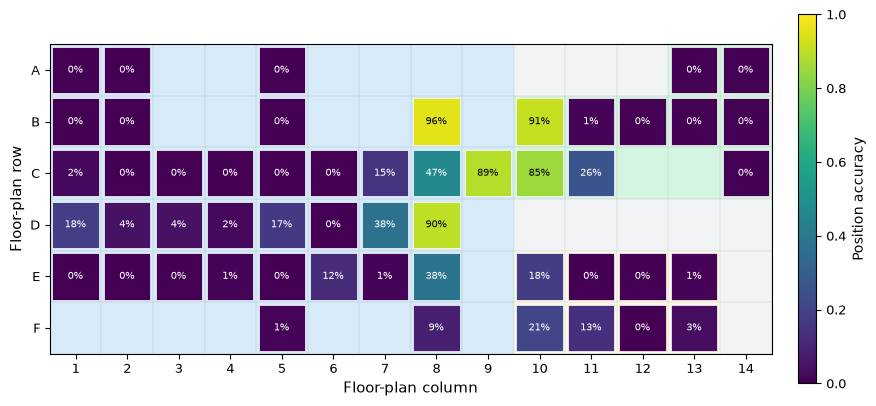

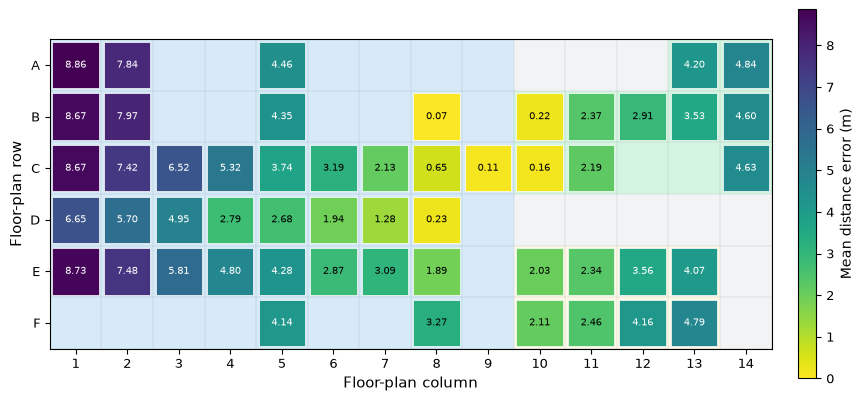

[Ideal]


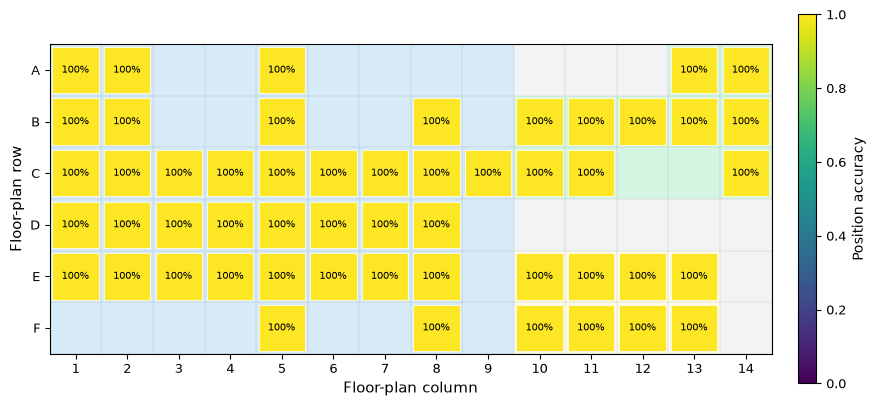

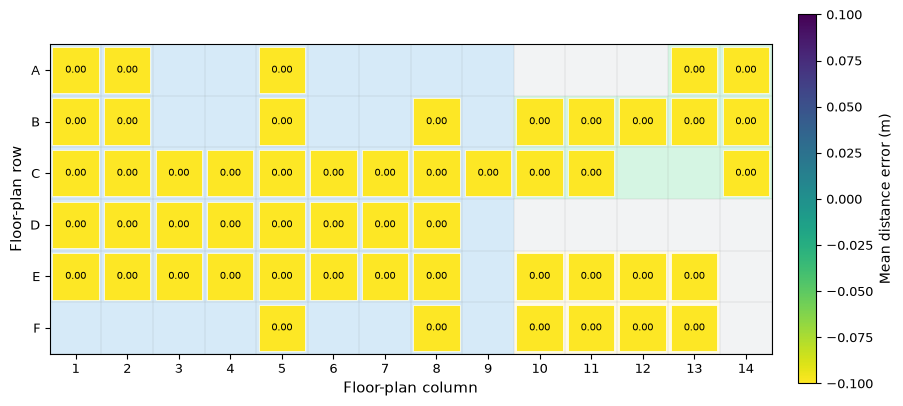

In [9]:
map_views = {"Measured": rf_predictions[MAIN_RUN]}
if SHOW_IDEAL:
    map_views["Ideal"] = rf_predictions["ideal (perfect classifier)"]
for view, predictions in map_views.items():
    print(f"[{view}]")
    plot_floor_plan_heatmap(
        predictions,
        save_path=(
            plots_dir / f"ml-cross_session-rf-fusion-3users-floor_heatmap-{view.lower()}.pdf"
            if SAVE_PLOTS
            else None
        ),
        show=DISPLAY_PLOTS,
    )

## 3. Shift versus Error

Per (volunteer, position): the full-dimensional `shift_ratio` (median across ESPs, `empty_baseline`, see `Fingerprint_Analysis.ipynb` section 6) against the main run's localization performance. Spearman ρ is given pooled (`all`, n ≈ 156) and per volunteer (n ≈ 52).

User 01's E-5 is a same-day pair normalized with the 16-07 baseline (see the known issues).

Ideal: every point in the corner with low shift and perfect localization. The correlation is undefined there, since nothing varies.

In [10]:
session_df = filter_users(feature_dataframes[RF_BAND], SESSION_USERS)
shift_frames = {"Measured": session_df}
if SHOW_IDEAL:
    shift_frames["Ideal"] = ideal_reference_features(
        session_df, template_trial=TRIAL_A, noise_scale=IDEAL_NOISE_SCALE, random_state=RANDOM_STATE
    )
shift_localization = {}
for view, frame in shift_frames.items():
    view_similarity = cross_session_similarity(
        frame, feature_family=SIMILARITY_FEATURE_FAMILY, trials=COMPARISON_TRIALS
    )
    shift_localization[view] = shift_localization_table(
        location_shift_table(view_similarity), localization_by_location(map_views[view])
    )

shift_correlations = shift_localization_correlations(
    shift_localization["Measured"], performance_metrics=PERFORMANCE_METRICS
)
display(
    shift_correlations.loc[shift_correlations["shift_metric"].eq(SHIFT_METRIC)]
    .pivot_table(index="performance_metric", columns="user", values="spearman_rho")
    .round(2)
)
display(shift_localization["Measured"].query("user == '01' and location == 'E-5'"))

user,01,03,05,all
performance_metric,,,,
mean_distance_error,0.39,0.43,0.76,0.49
position_accuracy,-0.53,-0.41,-0.45,-0.43


,user,location,room,pearson_r,rmse,mean_offset,scale_ratio,smd,shift_ratio,windows,position_accuracy,room_accuracy,mean_distance_error,median_distance_error
42,01,E-5,1,0.280679,0.292918,-0.046532,1.84309,2.307266,2.395982,30,0.0,1.0,4.242641,4.242641


[Measured]


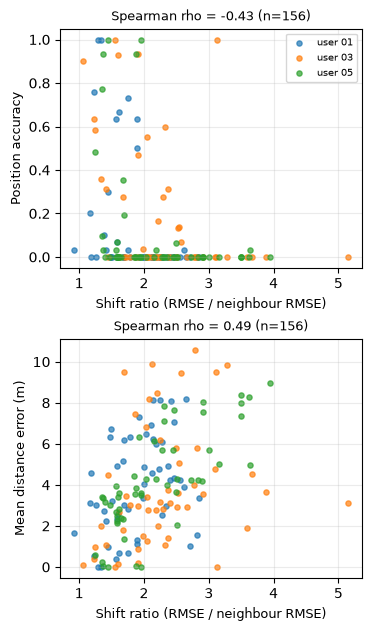

[Ideal]


/home/pedro.monteiro@co.it.pt/Desktop/thesis-project/utils/plots.py:3210: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(valid[shift_metric], valid[performance_metric]).statistic
/home/pedro.monteiro@co.it.pt/Desktop/thesis-project/utils/plots.py:3210: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(valid[shift_metric], valid[performance_metric]).statistic


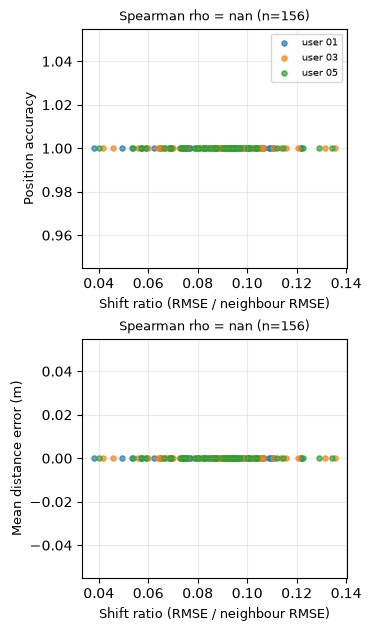

In [11]:
for view, table in shift_localization.items():
    print(f"[{view}]")
    plot_shift_vs_localization(
        table,
        shift_metrics=(SHIFT_METRIC,),
        performance_metrics=PERFORMANCE_METRICS,
        labels={**SHIFT_METRIC_LABELS, **PERFORMANCE_LABELS},
        save_path=(
            plots_dir / f"shift_vs_localization-rf-fusion-3users-{view.lower()}.pdf"
            if SAVE_PLOTS
            else None
        ),
        show=DISPLAY_PLOTS,
    )

## 4. Save Tables

In [12]:
if SAVE_TABLES:
    save_table(localization_summary, tables_dir, "localization-rf-fusion-runs")
    save_table(shift_localization["Measured"], tables_dir, "shift_vs_localization-rf-fusion-3users")
    save_table(shift_correlations, tables_dir, "shift_vs_localization-correlations-3users")
else:
    print("Tables not saved because SAVE_TABLES is False.")

Tables not saved because SAVE_TABLES is False.
